# Ajuste Direto contracts

Contracts whose `tipo_procedimento` is an Ajuste Direto variant. Four verbatim values exist:

- `Ajuste Direto Regime Geral` — 1 316 104
- `Ajuste direto simplificado ao abrigo da Lei n.º 30/2021, de 21.05` — 3 111
- `Ajuste Direto Regime Geral ao abrigo do artigo 7º da Lei n.º 30/2021, de 21.05` — 46
- `Ajuste direto simplificado` — 37 935

**Rule:** `tipo_procedimento.str.to_lowercase().str.starts_with("ajuste direto")` (casing is inconsistent,
so no exact-equality list). Reference: **1 357 196 rows (59.5 % of 2 282 416)** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=2,295,074  cols=30
disregarded 12,658 contracts with |preco_contratual| < €10 (0.55%); kept 2,282,416
valor_por_dia defined for 97.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬─────────┐
│ adjudicante_key_source ┆ count   │
│ ---                    ┆ ---     │
│ str                    ┆ u32     │
╞════════════════════════╪═════════╡
│ nipc                   ┆ 2282390 │
│ name                   ┆ 26      │
└────────────────────────┴─────────┘


In [3]:
AD_EXPR = pl.col("tipo_procedimento").str.to_lowercase().str.starts_with("ajuste direto")
contracts["tipo_procedimento"].value_counts(sort=True)


tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",1316104
"""Consulta Prévia""",331977
"""Concurso público""",266980
"""Ao abrigo de acordo-quadro (ar…",225281
"""Ao abrigo de acordo-quadro (ar…",49652
"""Contratação excluída II""",40152
"""Ajuste direto simplificado""",37935
"""Concurso limitado por prévia q…",4381
"""Setores especiais – isenção pa…",3937


In [4]:
ajuste = contracts.filter(AD_EXPR)
print(f"Ajuste Direto rows: {ajuste.height:,}  share by count: {ajuste.height / contracts.height:.1%}  "
      f"share by value: {ajuste['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = ajuste["tipo_procedimento"].value_counts(sort=True)
assert variants["count"].sum() == ajuste.height and ajuste.height < contracts.height
variants


Ajuste Direto rows: 1,357,196  share by count: 59.5%  share by value: 22.4%


tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",1316104
"""Ajuste direto simplificado""",37935
"""Ajuste direto simplificado ao …",3111
"""Ajuste Direto Regime Geral ao …",46


In [5]:
# Effect of disregarding contracts with |value| below €10 on Ajuste Direto.
before = contracts_all.filter(AD_EXPR)
display(value_impact(before, ajuste))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",1.364253e6,1.357196e6,-7057.0,-0.52
"""mean_value""",26195.179236,26331.370191,136.190955,0.52
"""median_value""",8615.47,8700.0,84.53,0.98
"""total_value""",3.5737e10,3.5737e10,-21560.490005,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 45,527 of 1,357,196


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2.0,20.0,60.0,304.0,365.0,9.04,27.4,111.22,505.26,1817.5


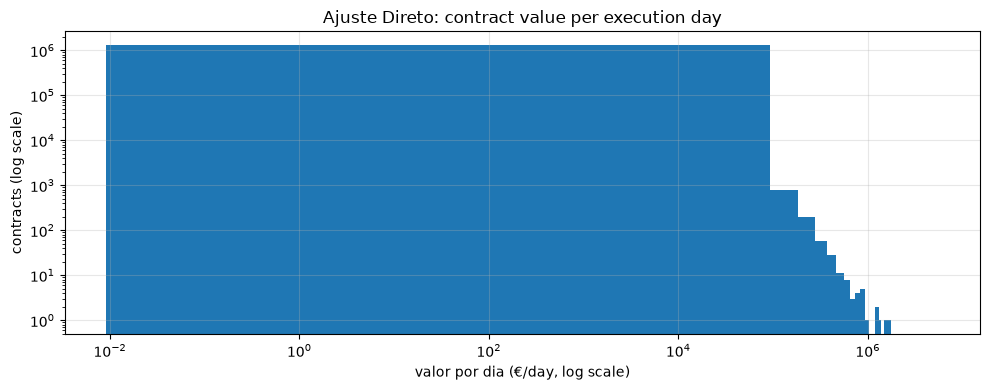

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = ajuste
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Ajuste Direto: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    ajuste.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",566472,6256.46,437.68,7.4116e9
"""91-365 d""",459304,10176.0,39.5,1.6564e10
"""31-90 d""",181070,12482.65,211.11,5.5302e9
"""366-3650 d""",104823,16500.0,21.91,5.8165e9


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(ajuste, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))


shape: (2, 2)
┌───────────────────────┬─────────┐
│ adjudicatarios_status ┆ count   │
│ ---                   ┆ ---     │
│ str                   ┆ u32     │
╞═══════════════════════╪═════════╡
│ YES                   ┆ 1187550 │
│ NO_NIF                ┆ 182194  │
└───────────────────────┴─────────┘
shape: (2, 2)
┌───────────────────────────┬─────────┐
│ adjudicatarios_key_source ┆ count   │
│ ---                       ┆ ---     │
│ str                       ┆ u32     │
╞═══════════════════════════╪═════════╡
│ nipc                      ┆ 1187550 │
│ name                      ┆ 182194  │
└───────────────────────────┴─────────┘


In [9]:
by_adjudicante = (
    ajuste.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(ajuste, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Ajuste Direto count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Ajuste Direto value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))


Top 20 adjudicantes by Ajuste Direto count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""506362299""",73826,6.8749e8,"""IPO Porto FG, EPE"""
"""508142156""",41316,4.7887e8,"""Unidade Local de Saúde de Gaia…"
"""508481287""",27594,1.4093e9,"""Unidade Local de Saúde de Sant…"
"""510103448""",27269,1.3408e9,"""Unidade Local de Saúde de Coim…"
"""508094461""",24610,1.6363e8,"""Unidade Local de Saúde do Alto…"
"""600012662""",23407,4.6836e8,"""MARINHA - Direção de Abastecim…"
"""510745997""",21653,4.5327e8,"""Unidade Local de Saúde do Alga…"
"""509822940""",18917,2.7085e8,"""Unidade Local de Saúde de Vise…"
"""506361470""",15869,3.2042e8,"""Unidade Local de Saúde de Alma…"



Top 20 adjudicantes by Ajuste Direto value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""508481287""",27594,1.4093e9,"""Unidade Local de Saúde de Sant…"
"""510103448""",27269,1.3408e9,"""Unidade Local de Saúde de Coim…"
"""503933813""",3330,1.1857e9,"""Infraestruturas de Portugal, S…"
"""506362299""",73826,6.8749e8,"""IPO Porto FG, EPE"""
"""508080142""",11806,6.8238e8,"""Unidade Local de Saúde de São …"
"""500051070""",14077,5.4159e8,"""Município de Lisboa"""
"""508142156""",41316,4.7887e8,"""Unidade Local de Saúde de Gaia…"
"""600012662""",23407,4.6836e8,"""MARINHA - Direção de Abastecim…"
"""509821197""",7574,4.5786e8,"""Unidade Local de Saúde de São …"


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(ajuste.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")


Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""501506543""",12229,1.3159e8,"""nipc""","""B BRAUN MEDICAL, LDA."""
"""504223933""",11265,2.6541e8,"""nipc""","""MEDTRONIC PORTUGAL, LDA"""
"""500153370""",8622,1.4785e8,"""nipc""","""JOHNSON & JOHNSON, LDA"""
"""504615947""",5555,2.0815e8,"""nipc""","""MEO - Serviços de Comunicações…"
"""500684324""",4798,7.0292e7,"""nipc""","""MEDICINÁLIA CORMÉDICA, LDA."""
"""504282921""",4561,1.5328e8,"""nipc""","""ROCHE SISTEMA DE DIAGNOSTICOS"""
"""503347345""",4304,1.1467e8,"""nipc""","""BAXTER MEDICO – FARMACEUTICA"""
"""500233810""",4157,3.6549e8,"""nipc""","""ROCHE FARMACÊUTICA QUIMICA, LD…"
"""504594214""",4149,4.9690e7,"""nipc""","""Stryker Portugal Produtos Médi…"



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""503604704""",2661,4.4383e8,"""nipc""","""GILEAD SCIENCES, LDA"""
"""500233810""",4157,3.6549e8,"""nipc""","""ROCHE FARMACÊUTICA QUIMICA, LD…"
"""500134960""",3941,3.1563e8,"""nipc""","""SANOFI- PRODUTOS FARMACÊUTICOS…"
"""500162166""",3680,2.9570e8,"""nipc""","""LAB. PFIZER, LDA."""
"""500189412""",2825,2.7623e8,"""nipc""","""JANSSEN CILAG FARMACEUTICA, LD…"
"""504223933""",11265,2.6541e8,"""nipc""","""MEDTRONIC PORTUGAL, LDA"""
"""500063524""",3266,2.6220e8,"""nipc""","""NOVARTIS FARMA-PROD.FARMACÊUTI…"
"""513300376""",1194,2.5354e8,"""nipc""","""PFIZER BIOFARMACEUTICA, SOCIED…"
"""513481613""",263,2.2551e8,"""nipc""","""VERTEX PHARMACEUTICALS (PORTUG…"


awardee entries keyed by name fallback: 182,194 of 1,369,744 (13.3%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = ajuste.group_by("adjudicante_key", "adjudicante_name").len()
new = ajuste.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    ajuste.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)


adjudicante rows: 9,611 (key, name spelling) -> 9,526 keys


adjudicatario rows: 396,779 (key, name) -> 163,876 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""501413197""",5,5814
"""508142156""",4,41316
"""508100496""",4,2740
"""600012662""",4,23407
"""508754275""",3,4626


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 1.357196e6    │
│ null_count ┆ 0.0           │
│ mean       ┆ 26331.370191  │
│ std        ┆ 260266.017242 │
│ min        ┆ -136999.8     │
│ 25%        ┆ 2560.0        │
│ 50%        ┆ 8700.0        │
│ 75%        ┆ 18930.0       │
│ max        ┆ 1.1139e8      │
└────────────┴───────────────┘


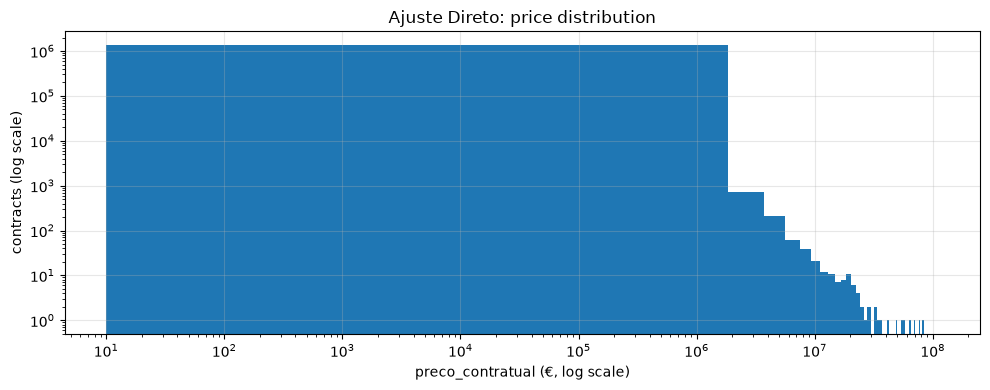

contracts above €5,000: 905,325
contracts above €20,000: 279,803
contracts above €75,000: 65,711


In [12]:
prices = ajuste["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Ajuste Direto: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")


In [13]:
print(f"fundament_ajuste_direto null rate: {ajuste['fundament_ajuste_direto'].null_count() / ajuste.height:.1%}")
ajuste["fundament_ajuste_direto"].value_counts(sort=True).head(15)


fundament_ajuste_direto null rate: 44.8%


fundament_ajuste_direto,count
str,u32
"""ausência de recursos próprios""",719712
null,608378
"""outros""",29106


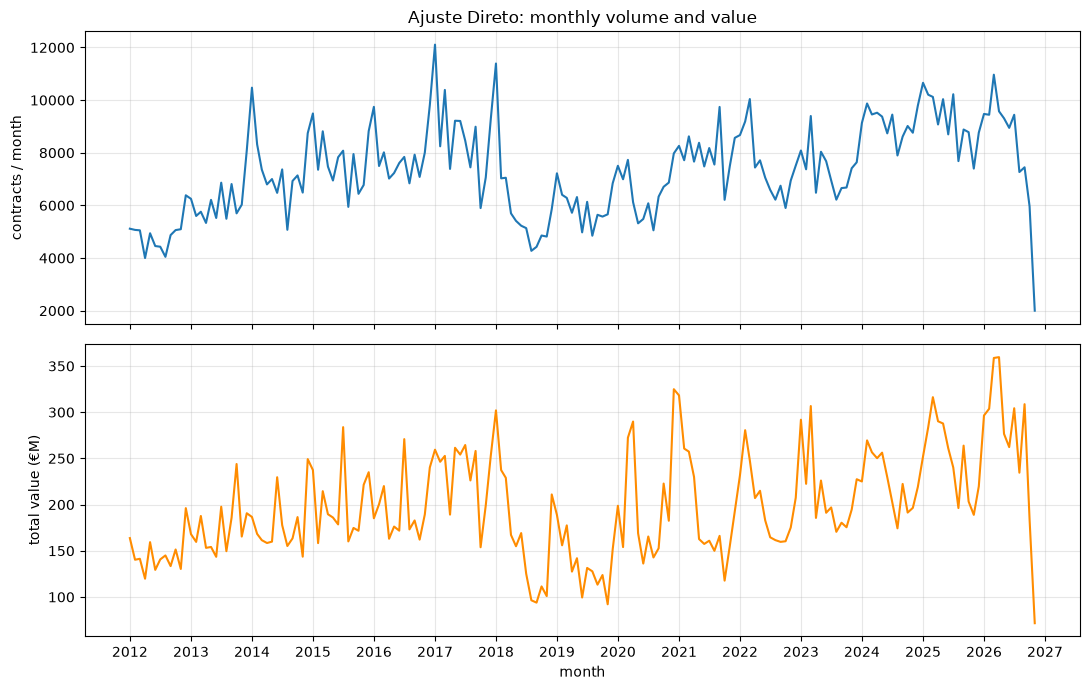

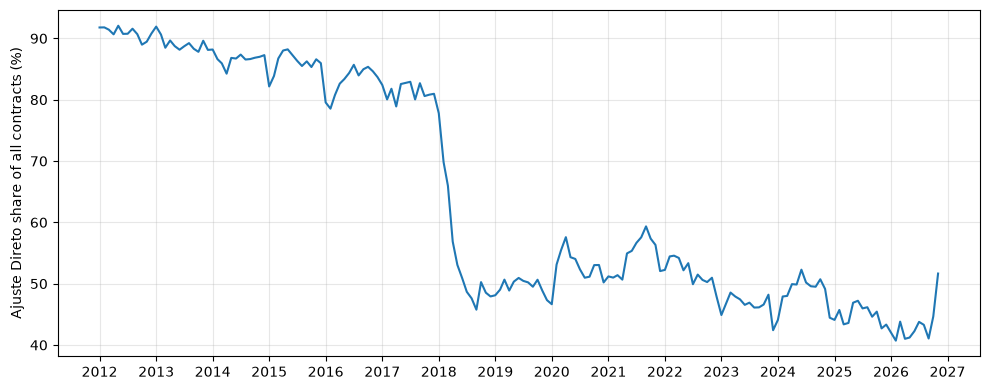

In [14]:
ad_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        AD_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(AD_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = ad_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Ajuste Direto: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(ad_monthly["month"], ad_monthly["share"] * 100)
ax.set_ylabel("Ajuste Direto share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
ajuste.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)


idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
848753,"""Associação de Municípios para …",1.1139e8,"""Ajuste Direto Regime Geral""",2013-10-03,"""A concessão tem por objecto o …"
1773655,"""Instituto Registos Notariado, …",8.2e7,"""Ajuste Direto Regime Geral""",2015-11-04,"""Aquisição de serviços para a p…"
1508437,"""DIREÇÃO-GERAL DE ARMAMENTO E I…",7.7e7,"""Ajuste Direto Regime Geral""",2015-07-22,"""Aquisição de Dois Navios Patru…"
2421726,"""MARINHA - Direção de Abastecim…",6.875e7,"""Ajuste Direto Regime Geral""",2016-07-21,"""REMOTORIZAÇÃO E UPGRADE DE AVI…"
11758845,"""Empresa de Electricidade dos A…",6.4529435e7,"""Ajuste Direto Regime Geral""",2025-09-30,"""Fornecimento de Fuelóleo às Ce…"
1150260,"""DEFLOC - Locação de Equipament…",5.6281926e7,"""Ajuste Direto Regime Geral""",2014-06-03,"""Prestação de serviços de manut…"
7491363,"""Direção-Geral da Saúde""",5.448966e7,"""Ajuste Direto Regime Geral""",2020-12-09,"""Fornecimento de doses de vacin…"
10942305,"""Empresa de Electricidade dos A…",4.9982e7,"""Ajuste Direto Regime Geral""",2024-09-28,"""Fornecimento de Fuelóleo às Ce…"
12796026,"""MARINHA - Direção de Abastecim…",4.23e7,"""Ajuste Direto Regime Geral""",2026-01-20,"""3025006631 Fornecimento de Sis…"


## Commentary and limitations

- `Ano` covers 2012–2026 (data up to 2026-11-14); edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- The €5 000 / €20 000 / €75 000 lines are informal reference points, not legal thresholds.
- Very large values may be outliers or data-entry errors.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`, blocked by first token/length) and may over- or under-merge; see `key_source`.
- Dirty NIPCs (wrong length, stray characters) are kept as separate keys, not merged by name.

- Contracts with |value| below €10 (`MIN_VALUE`, applied to the absolute value) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.